<a href="https://colab.research.google.com/github/jha-rishika/Google-Colab-ML/blob/main/ass7_23_11.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

First 5 Records:
       CGPA   IQ  Aptitude  Technical  Communication  Placement
0  6.872701   80        44         68             46          0
1  9.753572   98        95         82             76          1
2  8.659970   81        61         71             52          1
3  7.993292  132        92         87             43          1
4  5.780093  123        80         68             95          0

Dataset Shape: (150, 6)

Missing Values:
CGPA             0
IQ               0
Aptitude         0
Technical        0
Communication    0
Placement        0
dtype: int64

Duplicate Records: 0

Dataset after Cleaning: (150, 6)

Placement Distribution:
Placement
0    103
1     47
Name: count, dtype: int64

Independent Variables:
       CGPA   IQ  Aptitude  Technical  Communication
0  6.872701   80        44         68             46
1  9.753572   98        95         82             76
2  8.659970   81        61         71             52
3  7.993292  132        92         87             43
4  5.7

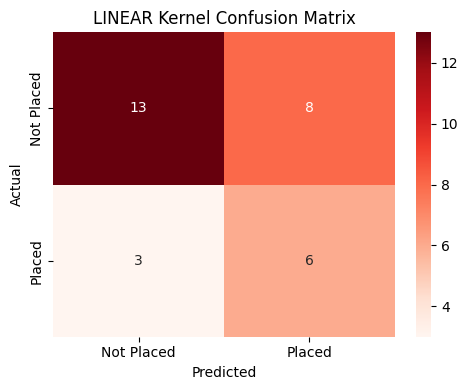


Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.81      0.62      0.70        21
      Placed       0.43      0.67      0.52         9

    accuracy                           0.63        30
   macro avg       0.62      0.64      0.61        30
weighted avg       0.70      0.63      0.65        30

SVM Kernel: poly
Accuracy : 0.6333
Precision: 0.4167
Recall   : 0.5556
F1-Score : 0.4762


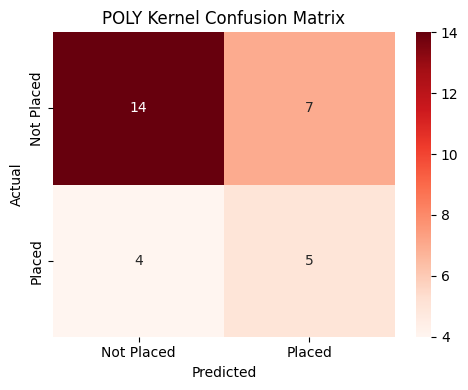


Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.78      0.67      0.72        21
      Placed       0.42      0.56      0.48         9

    accuracy                           0.63        30
   macro avg       0.60      0.61      0.60        30
weighted avg       0.67      0.63      0.65        30

SVM Kernel: rbf
Accuracy : 0.7333
Precision: 0.5385
Recall   : 0.7778
F1-Score : 0.6364


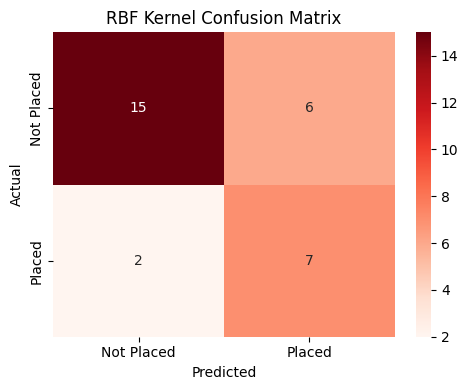


Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.88      0.71      0.79        21
      Placed       0.54      0.78      0.64         9

    accuracy                           0.73        30
   macro avg       0.71      0.75      0.71        30
weighted avg       0.78      0.73      0.74        30

SVM Kernel: sigmoid
Accuracy : 0.6333
Precision: 0.4444
Recall   : 0.8889
F1-Score : 0.5926


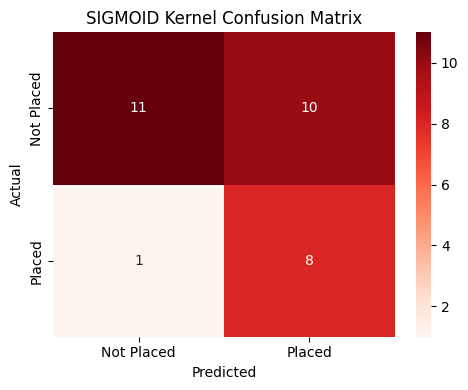


Classification Report:
              precision    recall  f1-score   support

  Not Placed       0.92      0.52      0.67        21
      Placed       0.44      0.89      0.59         9

    accuracy                           0.63        30
   macro avg       0.68      0.71      0.63        30
weighted avg       0.78      0.63      0.64        30

 Kernel  Accuracy  Precision   Recall  F1-Score
 linear  0.633333   0.428571 0.666667  0.521739
   poly  0.633333   0.416667 0.555556  0.476190
    rbf  0.733333   0.538462 0.777778  0.636364
sigmoid  0.633333   0.444444 0.888889  0.592593

Best Performing Kernel: rbf


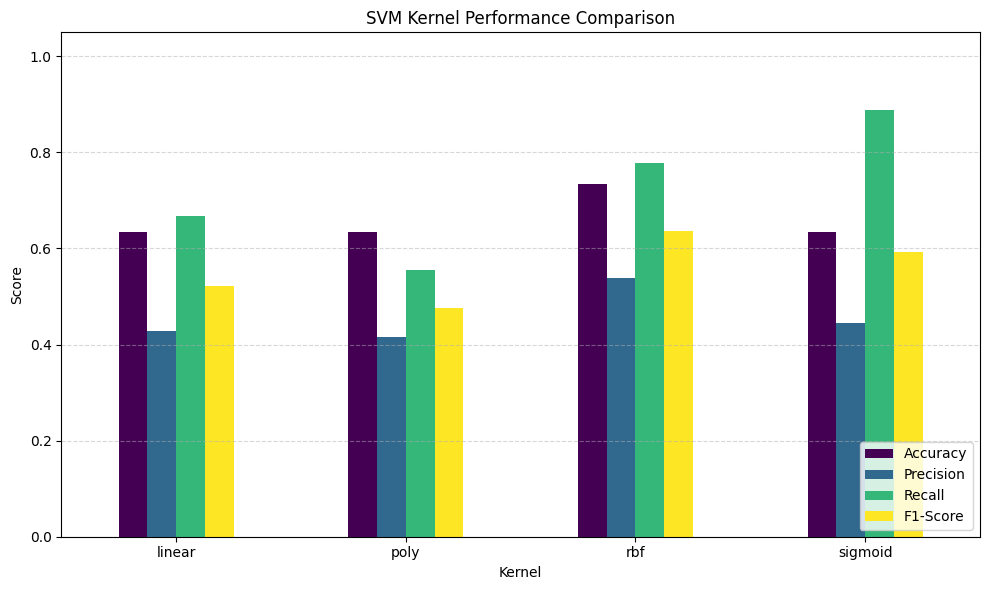

 CGPA  IQ  Aptitude  Technical  Communication  Prediction Placement Status
  8.5 120        85         90             80           1           Placed
  6.0  95        50         45             55           0       Not Placed
  7.8 130        75         80             75           1           Placed
  5.5  85        40         50             45           0       Not Placed
  9.2 140        95         92             90           1           Placed

Program Completed Successfully!


In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

np.random.seed(42)

data = pd.DataFrame({
    'CGPA': np.random.uniform(5, 10, 150),
    'IQ': np.random.randint(80, 150, 150),
    'Aptitude': np.random.randint(30, 100, 150),
    'Technical': np.random.randint(30, 100, 150),
    'Communication': np.random.randint(30, 100, 150)
})

data['Placement'] = (
    (data['CGPA'] >= 7) &
    (
        data['Aptitude'] +
        data['Technical'] +
        data['Communication'] >= 180
    )
).astype(int)

print("First 5 Records:")
print(data.head())

print("\nDataset Shape:", data.shape)

print("\nMissing Values:")
print(data.isnull().sum())

print("\nDuplicate Records:", data.duplicated().sum())

data.drop_duplicates(inplace=True)
data.dropna(inplace=True)

print("\nDataset after Cleaning:", data.shape)

print("\nPlacement Distribution:")
print(data['Placement'].value_counts())

X = data.drop('Placement', axis=1)
y = data['Placement']

print("\nIndependent Variables:")
print(X.head())

print("\nDependent Variable:")
print(y.head())

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

kernels = ['linear', 'poly', 'rbf', 'sigmoid']

results = []
models = {}

for kernel in kernels:

    print("SVM Kernel:", kernel)

    model = SVC(
        kernel=kernel,
        random_state=42,
        class_weight='balanced'
    )

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    models[kernel] = model

    accuracy = accuracy_score(y_test, y_pred)

    precision = precision_score(
        y_test, y_pred, zero_division=0
    )

    recall = recall_score(
        y_test, y_pred, zero_division=0
    )

    f1 = f1_score(
        y_test, y_pred, zero_division=0
    )

    results.append({
        'Kernel': kernel,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1
    })

    print("Accuracy :", round(accuracy, 4))
    print("Precision:", round(precision, 4))
    print("Recall   :", round(recall, 4))
    print("F1-Score :", round(f1, 4))

    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=[0, 1]
    )

    plt.figure(figsize=(5, 4))

    sns.heatmap(
        cm,
        annot=True,
        fmt='d',
        cmap='Reds',
        xticklabels=['Not Placed', 'Placed'],
        yticklabels=['Not Placed', 'Placed']
    )

    plt.title(kernel.upper() + ' Kernel Confusion Matrix')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.tight_layout()
    plt.show()

    print("\nClassification Report:")

    print(classification_report(
        y_test,
        y_pred,
        labels=[0, 1],
        target_names=['Not Placed', 'Placed'],
        zero_division=0
    ))

results_df = pd.DataFrame(results)

print(results_df.to_string(index=False))

best_kernel = results_df.loc[
    results_df['F1-Score'].idxmax(),
    'Kernel'
]

best_model = models[best_kernel]

print("\nBest Performing Kernel:", best_kernel)

metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score']

results_df.set_index('Kernel')[metrics].plot(
    kind='bar',
    figsize=(10, 6),
    ylim=(0, 1.05),
    colormap='viridis'
)

plt.title('SVM Kernel Performance Comparison')
plt.xlabel('Kernel')
plt.ylabel('Score')
plt.xticks(rotation=0)
plt.legend(loc='lower right')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

new_students = pd.DataFrame({
    'CGPA': [8.5, 6.0, 7.8, 5.5, 9.2],
    'IQ': [120, 95, 130, 85, 140],
    'Aptitude': [85, 50, 75, 40, 95],
    'Technical': [90, 45, 80, 50, 92],
    'Communication': [80, 55, 75, 45, 90]
})

new_students = new_students[X.columns]

new_students_scaled = scaler.transform(new_students)

predictions = best_model.predict(new_students_scaled)

new_students['Prediction'] = predictions

new_students['Placement Status'] = (
    new_students['Prediction'].map({
        0: 'Not Placed',
        1: 'Placed'
    })
)
print(new_students.to_string(index=False))

print("\nProgram Completed Successfully!")